In [1]:
import numpy as np
import pandas as pd
import time
from annoy import AnnoyIndex
import faiss
import hnswlib
import matplotlib.pyplot as plt

In [2]:
# ===============================
# Konfigurasi percobaan
# ===============================
configs = [(1_000, 2), (1_000, 5), (1_000_000, 2), (1_000_000, 5)]
metrics = ['euclidean', 'manhattan', 'cosine']
nq = 100   # jumlah query
k = 10     # jumlah tetangga

ANNOY_METRIC = {'euclidean': 'euclidean', 'manhattan': 'manhattan', 'cosine': 'angular'}
FAISS_METRIC = {'euclidean': faiss.METRIC_L2, 'manhattan': faiss.METRIC_L1, 'cosine': faiss.METRIC_INNER_PRODUCT}
HNSW_METRIC  = {'euclidean': 'l2', 'manhattan': None, 'cosine': 'cosine'}

In [3]:
# ===============================
# Fungsi bantu
# ===============================
def normalize(v):
    return v / np.linalg.norm(v, axis=1, keepdims=True)

def exact_dist(X, q, ids, metric):
    # Jarak eksak query q ke titik-titik X[ids] (dalam float64)
    P = X[np.asarray(ids, dtype=np.int64)].astype(np.float64)
    q = q.astype(np.float64)
    if metric == 'euclidean':
        return np.linalg.norm(P - q, axis=1)
    if metric == 'manhattan':
        return np.abs(P - q).sum(axis=1)
    return 1 - (P @ q) / (np.linalg.norm(P, axis=1) * np.linalg.norm(q))

def ground_truth(X, Q, metric):
    # Exact NN (brute force) sebagai acuan recall -> jarak tetangga ke-k tiap query
    dim = X.shape[1]
    if metric == 'cosine':
        index = faiss.IndexFlatIP(dim)
        index.add(normalize(X))
        _, I = index.search(normalize(Q), k)
    else:
        index = faiss.IndexFlat(dim, FAISS_METRIC[metric])
        index.add(X)
        _, I = index.search(Q, k)
    return np.array([exact_dist(X, q, ids, metric).max() for q, ids in zip(Q, I)])

def recall_at_k(X, Q, I_pred, kth_dist, metric):
    # Recall berbasis jarak: tetangga hasil ANN dianggap benar jika jaraknya <= jarak
    # tetangga ke-k exact NN. Ini menangani "tie" (banyak titik berjarak sama), yang
    # terjadi pada cosine 2D dengan 1 juta data (beda sudut di bawah presisi float32).
    correct = 0
    for q, ids, thr in zip(Q, I_pred, kth_dist):
        d = exact_dist(X, q, ids[:k], metric)
        correct += int((d <= thr * (1 + 1e-6) + 1e-9).sum())
    return correct / (len(Q) * k)

def timed_queries(search_fn, Q):
    # Query satu per satu, kembalikan (hasil, ms/query)
    start = time.time()
    I = [search_fn(q) for q in Q]
    elapsed = (time.time() - start) * 1000 / len(Q)
    return I, elapsed

In [4]:
# ===============================
# ANNOY
# ===============================
def run_annoy(X, Q, metric, n_trees=10):
    dim = X.shape[1]
    index = AnnoyIndex(dim, ANNOY_METRIC[metric])
    start = time.time()
    for i in range(len(X)):
        index.add_item(i, X[i])
    index.build(n_trees)
    build_time = time.time() - start

    I, q_time = timed_queries(lambda q: index.get_nns_by_vector(q, k), Q)
    return build_time, q_time, I

# ===============================
# FAISS (IVF Flat)
# ===============================
def run_faiss(X, Q, metric, nprobe=10):
    dim = X.shape[1]
    if metric == 'cosine':
        X, Q = normalize(X), normalize(Q)
    nlist = int(np.sqrt(len(X)))
    quantizer = faiss.IndexFlat(dim, FAISS_METRIC[metric])
    index = faiss.IndexIVFFlat(quantizer, dim, nlist, FAISS_METRIC[metric])
    start = time.time()
    index.train(X)
    index.add(X)
    build_time = time.time() - start

    index.nprobe = nprobe
    I, q_time = timed_queries(lambda q: index.search(q.reshape(1, -1), k)[1][0], Q)
    return build_time, q_time, I

# ===============================
# HNSW (hnswlib)
# ===============================
def run_hnsw(X, Q, metric, M=16, ef_construction=200, ef=50):
    if HNSW_METRIC[metric] is None:
        return None   # metric tidak didukung hnswlib
    dim = X.shape[1]
    index = hnswlib.Index(space=HNSW_METRIC[metric], dim=dim)
    start = time.time()
    index.init_index(max_elements=len(X), ef_construction=ef_construction, M=M)
    index.add_items(X)
    build_time = time.time() - start

    index.set_ef(ef)
    I, q_time = timed_queries(lambda q: index.knn_query(q, k=k)[0][0], Q)
    return build_time, q_time, I

In [5]:
# ===============================
# Jalankan seluruh percobaan
# ===============================
runners = {'ANNOY': run_annoy, 'FAISS': run_faiss, 'HNSW': run_hnsw}
results = []

for n_data, dim in configs:
    np.random.seed(42)
    X = np.random.random((n_data, dim)).astype(np.float32)
    Q = np.random.random((nq, dim)).astype(np.float32)

    for metric in metrics:
        gt = ground_truth(X, Q, metric)
        for algo, fn in runners.items():
            out = fn(X, Q, metric)
            if out is None:
                results.append(dict(data=n_data, dim=dim, metric=metric, algo=algo,
                                    build_s=np.nan, query_ms=np.nan, recall=np.nan))
                print(f"{n_data:>9}/{dim}D {metric:<9} {algo:<5} -> tidak didukung")
                continue
            build_s, query_ms, I = out
            rec = recall_at_k(X, Q, I, gt, metric)
            results.append(dict(data=n_data, dim=dim, metric=metric, algo=algo,
                                build_s=build_s, query_ms=query_ms, recall=rec))
            print(f"{n_data:>9}/{dim}D {metric:<9} {algo:<5} build={build_s:8.3f}s "
                  f"query={query_ms:7.4f}ms recall@{k}={rec:.3f}")

df = pd.DataFrame(results)
df['Jumlah Data/Dimensi'] = df['data'].astype(str) + '/' + df['dim'].astype(str) + 'D'

     1000/2D euclidean ANNOY build=   0.020s query= 0.0226ms recall@10=0.996
     1000/2D euclidean FAISS build=   0.002s query= 0.0187ms recall@10=1.000
     1000/2D euclidean HNSW  build=   0.020s query= 0.0142ms recall@10=1.000
     1000/2D manhattan ANNOY build=   0.017s query= 0.0214ms recall@10=0.987
     1000/2D manhattan FAISS build=   0.004s query= 0.0264ms recall@10=1.000
     1000/2D manhattan HNSW  -> tidak didukung
     1000/2D cosine    ANNOY build=   0.018s query= 0.0189ms recall@10=0.997
     1000/2D cosine    FAISS build=   0.005s query= 0.0179ms recall@10=1.000
     1000/2D cosine    HNSW  build=   0.018s query= 0.0188ms recall@10=1.000
     1000/5D euclidean ANNOY build=   0.012s query= 0.0187ms recall@10=0.955
     1000/5D euclidean FAISS build=   0.001s query= 0.0171ms recall@10=0.997
     1000/5D euclidean HNSW  build=   0.025s query= 0.0178ms recall@10=1.000


WARNING clustering 1000 points to 31 centroids: please provide at least 1209 training points
WARNING clustering 1000 points to 31 centroids: please provide at least 1209 training points
WARNING clustering 1000 points to 31 centroids: please provide at least 1209 training points
WARNING clustering 1000 points to 31 centroids: please provide at least 1209 training points


     1000/5D manhattan ANNOY build=   0.015s query= 0.0192ms recall@10=0.942
     1000/5D manhattan FAISS build=   0.002s query= 0.0202ms recall@10=0.996
     1000/5D manhattan HNSW  -> tidak didukung
     1000/5D cosine    ANNOY build=   0.020s query= 0.0203ms recall@10=0.985
     1000/5D cosine    FAISS build=   0.001s query= 0.0172ms recall@10=1.000
     1000/5D cosine    HNSW  build=   0.025s query= 0.0180ms recall@10=1.000


WARNING clustering 1000 points to 31 centroids: please provide at least 1209 training points
WARNING clustering 1000 points to 31 centroids: please provide at least 1209 training points


  1000000/2D euclidean ANNOY build=  10.009s query= 0.0733ms recall@10=0.995


  1000000/2D euclidean FAISS build=   0.665s query= 0.1361ms recall@10=1.000


... (10 outputs left out)

  1000000/5D manhattan FAISS build=  11.367s query= 0.2048ms recall@10=1.000
  1000000/5D manhattan HNSW  -> tidak didukung


  1000000/5D cosine    ANNOY build=  11.516s query= 0.0579ms recall@10=0.982


  1000000/5D cosine    FAISS build=   4.530s query= 0.2441ms recall@10=1.000


  1000000/5D cosine    HNSW  build=  55.127s query= 0.0456ms recall@10=1.000


## Tabel Hasil

In [6]:
def pivot(col, fmt):
    t = df.pivot_table(index=['Jumlah Data/Dimensi', 'metric'], columns='algo', values=col,
                       sort=False, dropna=False)
    t = t[['ANNOY', 'FAISS', 'HNSW']]
    return t.map(lambda v: 'N/A' if pd.isna(v) else fmt.format(v))

print("=== Query time (ms/query) ===")
display(pivot('query_ms', '{:.4f}'))

=== Query time (ms/query) ===


algo                            ANNOY   FAISS    HNSW
Jumlah Data/Dimensi metric                           
1000/2D             euclidean  0.0226  0.0187  0.0142
                    manhattan  0.0214  0.0264     N/A
                    cosine     0.0189  0.0179  0.0188
1000/5D             euclidean  0.0187  0.0171  0.0178
                    manhattan  0.0192  0.0202     N/A
                    cosine     0.0203  0.0172  0.0180
1000000/2D          euclidean  0.0733  0.1361  0.0266
                    manhattan  0.0556  0.1349     N/A
                    cosine     0.0524  0.1478  0.0496
1000000/5D          euclidean  0.0479  0.1431  0.0481
                    manhattan  0.0660  0.2048     N/A
                    cosine     0.0579  0.2441  0.0456

In [7]:
print("=== Build time (detik) ===")
display(pivot('build_s', '{:.3f}'))

=== Build time (detik) ===


algo                            ANNOY   FAISS    HNSW
Jumlah Data/Dimensi metric                           
1000/2D             euclidean   0.020   0.002   0.020
                    manhattan   0.017   0.004     N/A
                    cosine      0.018   0.005   0.018
1000/5D             euclidean   0.012   0.001   0.025
                    manhattan   0.015   0.002     N/A
                    cosine      0.020   0.001   0.025
1000000/2D          euclidean  10.009   0.665  35.235
                    manhattan  10.597  13.761     N/A
                    cosine     34.056   1.780  51.030
1000000/5D          euclidean   8.960   1.136  54.189
                    manhattan   8.832  11.367     N/A
                    cosine     11.516   4.530  55.127

In [8]:
print(f"=== Recall@{k} ===")
display(pivot('recall', '{:.3f}'))

=== Recall@10 ===


algo                           ANNOY  FAISS   HNSW
Jumlah Data/Dimensi metric                        
1000/2D             euclidean  0.996  1.000  1.000
                    manhattan  0.987  1.000    N/A
                    cosine     0.997  1.000  1.000
1000/5D             euclidean  0.955  0.997  1.000
                    manhattan  0.942  0.996    N/A
                    cosine     0.985  1.000  1.000
1000000/2D          euclidean  0.995  1.000  1.000
                    manhattan  0.991  1.000    N/A
                    cosine     0.976  0.993  0.904
1000000/5D          euclidean  0.950  1.000  1.000
                    manhattan  0.891  1.000    N/A
                    cosine     0.982  1.000  1.000

In [9]:
# Tabel gabungan: query time (ms) | recall
combo = df.copy()
combo['hasil'] = combo.apply(lambda r: 'N/A' if pd.isna(r.query_ms)
                             else f"{r.query_ms:.4f} ms | R={r.recall:.2f} | build {r.build_s:.2f}s", axis=1)
summary = combo.pivot_table(index=['Jumlah Data/Dimensi', 'metric'], columns='algo',
                            values='hasil', aggfunc='first', sort=False)[['ANNOY', 'FAISS', 'HNSW']]
display(summary)

algo                                                       ANNOY  \
Jumlah Data/Dimensi metric                                         
1000/2D             euclidean   0.0226 ms | R=1.00 | build 0.02s   
                    manhattan   0.0214 ms | R=0.99 | build 0.02s   
                    cosine      0.0189 ms | R=1.00 | build 0.02s   
1000/5D             euclidean   0.0187 ms | R=0.95 | build 0.01s   
                    manhattan   0.0192 ms | R=0.94 | build 0.02s   
                    cosine      0.0203 ms | R=0.98 | build 0.02s   
1000000/2D          euclidean  0.0733 ms | R=0.99 | build 10.01s   
                    manhattan  0.0556 ms | R=0.99 | build 10.60s   
                    cosine     0.0524 ms | R=0.98 | build 34.06s   
1000000/5D          euclidean   0.0479 ms | R=0.95 | build 8.96s   
                    manhattan   0.0660 ms | R=0.89 | build 8.83s   
                    cosine     0.0579 ms | R=0.98 | build 11.52s   

algo                                                       FAISS  \
Jumlah Data/Dimensi metric                                         
1000/2D             euclidean   0.0187 ms | R=1.00 | build 0.00s   
                    manhattan   0.0264 ms | R=1.00 | build 0.00s   
                    cosine      0.0179 ms | R=1.00 | build 0.00s   
1000/5D             euclidean   0.0171 ms | R=1.00 | build 0.00s   
                    manhattan   0.0202 ms | R=1.00 | build 0.00s   
                    cosine      0.0172 ms | R=1.00 | build 0.00s   
1000000/2D          euclidean   0.1361 ms | R=1.00 | build 0.67s   
                    manhattan  0.1349 ms | R=1.00 | build 13.76s   
                    cosine      0.1478 ms | R=0.99 | build 1.78s   
1000000/5D          euclidean   0.1431 ms | R=1.00 | build 1.14s   
                    manhattan  0.2048 ms | R=1.00 | build 11.37s   
                    cosine      0.2441 ms | R=1.00 | build 4.53s   

algo                                                        HNSW  
Jumlah Data/Dimensi metric                                        
1000/2D             euclidean   0.0142 ms | R=1.00 | build 0.02s  
                    manhattan                                N/A  
                    cosine      0.0188 ms | R=1.00 | build 0.02s  
1000/5D             euclidean   0.0178 ms | R=1.00 | build 0.03s  
                    manhattan                                N/A  
                    cosine      0.0180 ms | R=1.00 | build 0.03s  
1000000/2D          euclidean  0.0266 ms | R=1.00 | build 35.24s  
                    manhattan                                N/A  
                    cosine     0.0496 ms | R=0.90 | build 51.03s  
1000000/5D          euclidean  0.0481 ms | R=1.00 | build 54.19s  
                    manhattan                                N/A  
                    cosine     0.0456 ms | R=1.00 | build 55.13s

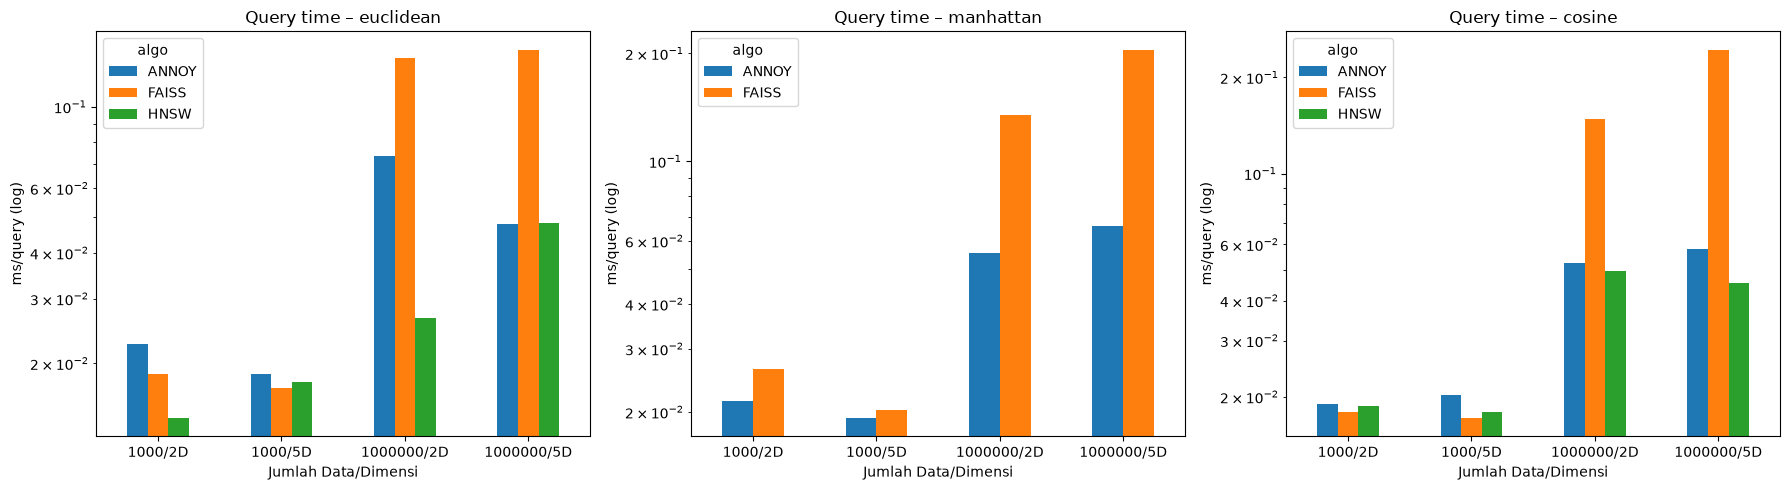

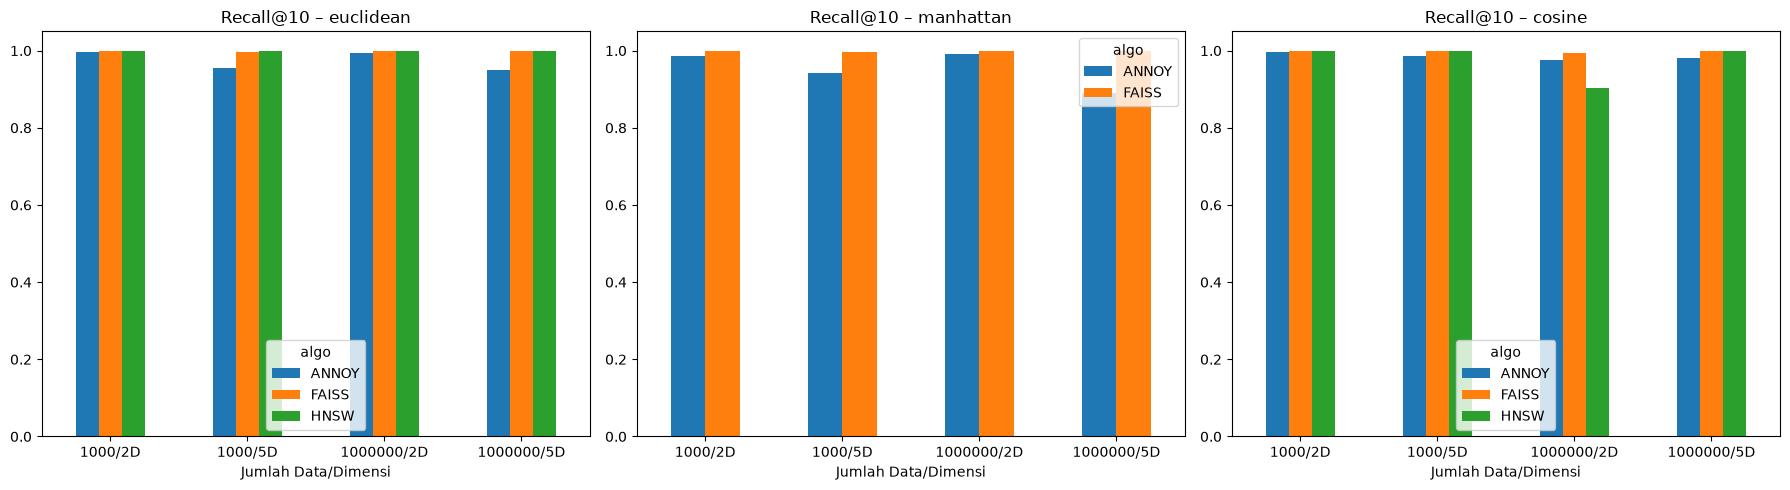

In [10]:
# ===============================
# Visualisasi
# ===============================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, metrics):
    sub = df[df.metric == metric].pivot_table(index='Jumlah Data/Dimensi', columns='algo',
                                              values='query_ms', sort=False)
    sub.plot(kind='bar', ax=ax, logy=True, rot=0)
    ax.set_title(f"Query time – {metric}")
    ax.set_ylabel("ms/query (log)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, metric in zip(axes, metrics):
    sub = df[df.metric == metric].pivot_table(index='Jumlah Data/Dimensi', columns='algo',
                                              values='recall', sort=False)
    sub.plot(kind='bar', ax=ax, rot=0, ylim=(0, 1.05))
    ax.set_title(f"Recall@{k} – {metric}")
plt.tight_layout()
plt.show()

## Analisis

**1. Pengaruh jumlah data (1.000 → 1.000.000)**
- Pada 1.000 data, ketiga algoritma punya query time hampir sama (~0,02 ms) karena overhead pemanggilan Python lebih dominan daripada pencarian.
- Pada 1.000.000 data, perbedaannya terlihat: **HNSW** paling cepat saat query (~0,03–0,05 ms), **ANNOY** di dekatnya (~0,05–0,07 ms), sedangkan **FAISS IVF** paling lambat (~0,13–0,24 ms) karena harus memindai `nprobe=10` cluster yang masing-masing berisi ~1.000 vektor.
- Build time berbanding terbalik: **FAISS** paling cepat (≈1 detik untuk L2), **ANNOY** ±9–34 detik, **HNSW** paling lama (±35–55 detik) karena harus membangun graf berlapis.

**2. Pengaruh dimensi (2D → 5D)**
- Recall ANNOY turun ketika dimensi naik (Euclidean 0,995 → 0,950; Manhattan 0,991 → 0,891 pada 1 juta data): hyperplane acak lebih sulit memisahkan ruang yang lebih tinggi dengan hanya 10 pohon.
- FAISS dan HNSW tetap memiliki recall ≈1,0 di 5D.

**3. Pengaruh metric distance**
- **Euclidean**: didukung semua algoritma; recall FAISS dan HNSW ≈1,0.
- **Manhattan**: hnswlib tidak mendukung (hanya `l2`, `ip`, `cosine`). Pada FAISS build time naik drastis (0,7 detik → ±11–14 detik) karena k-means dengan L1 jauh lebih mahal.
- **Cosine**: pada 2D dengan 1 juta data, banyak titik memiliki arah (sudut) yang hampir sama, sehingga recall HNSW turun (0,904) dan build time ANNOY/HNSW meningkat. Pada 5D masalah ini tidak terjadi.

**Kesimpulan**
- Query tercepat dengan recall tinggi untuk data besar → **HNSW** (dengan konsekuensi build lama dan tidak mendukung Manhattan).
- Build tercepat dan recall paling stabil di semua metric → **FAISS**, tetapi query lebih lambat dengan parameter `nprobe=10`.
- **ANNOY** menjadi kompromi (build sedang, query cepat), namun recall-nya paling sensitif terhadap kenaikan dimensi.
